### Retrospective Labelling - Hyperparameter Tuning (Version 2 - Log Loss)

* Using the findings of the best performing datasets in `model_compare_dataset`, I begin with hyperparameter tuning the model on its best performance

| Model | Transformation Variant | Dataset Variable |
| :--- | :--- | :--- |
| **LightGBM** | Raw | `train_raw` |
| **CatBoost** | Raw_removed_corr_var | `train_raw_removed_corr_var` |
| **Random Forest** | Raw_removed_corr_var | `train_raw_removed_corr_var` |
| **KNN** | YJ_robust_scaled | `train_yj_robust_scaled` |
| **Logistic Regression** | YJ_robust_scaled | `train_yj_robust_scaled` |
| **MLP Classifier** | YJ_robust_scaled | `train_yj_robust_scaled` |

* I ran randomised grid search on each model, and scored them by `neg_log_loss`
* Although the final metric for the model is evaluated in ROC-AUC, as this is just the data augmentation stage (augmenting NA rows with soft labels to become usable in the train dataset)
* I focus on neg_log_loss, as it reflects the the goal of predicting probabilities (soft labels)
* https://www.nb-data.com/p/why-you-should-use-log-loss-to-evaluate 
* https://codemia.io/knowledge-hub/path/scikit-learn_classification_on_soft_labels
* I will move towards roc_auc tuning in the next stage

----
#### Results
From Part 1 (tuning on pr-auc)
* Best Performing Model is LightGBM (performed the best on the holdout dataset (best PR_AUC, ROC_AUC, Precision, F1)), performance on Recall is onl second to CatBoost
* Best Parameters for LightGBM:
`{'model__scale_pos_weight': 3.0, 'model__num_leaves': 31, 'model__n_estimators': 500, 'model__min_child_samples': 50, 'model__max_depth': 20, 'model__learning_rate': 0.1}`

From Part 2 (tuning on log_loss)
* Best performing model is LightGBM (lowest holdout log loss, highest ROC-AUC, PR-AUC)
* Best parameters:
`{'model__scale_pos_weight': 3.0, 'model__num_leaves': 15, 'model__n_estimators': 500, 'model__min_child_samples': 20, 'model__max_depth': 10, 'model__learning_rate': 0.03}`
* to control for overfitting: LightGBM had a better log-loss metric in the holdout dataset than the CV dataset. If Overfitting had occurred, LightGBM would have performed worse on the holdout dataset

Assessment of pr-auc vs log-loss:
* Both tuned hyperparameters are assessed on the same hold-out dataset (for both files, train_test_split with random_state = 100)
* the hold-out dataset was not involved in the hyperparameter tuning for both log-loss and pr-auc
* HOWEVER, the same holdout dataset is used to select the best model (among the 6 choices) for both, thus the holdout dataset is not fully untouched
* however, the holdout dataset has not been used in model hyperparameter tuning, ensuring no data leakage
* as there is no other dataset available, I will be using this same hold-out dataset to evaluate and compare the performance between both pr-auc and log-loss best performing model

Comparison results:
* log-loss tuned:
  * had a better log loss
  * slightly better ROC-AUC
  * better recall

* pr-auc tuned:
  * slightly better PR-AUC
  * slightly better precision
  * slightly better F1
  
* for holdout PR_AUC, the score is the same

Holdout performance:
| model | holdout_log_loss | holdout_brier_score | holdout_ROC_AUC | holdout_PR_AUC | holdout_precision | holdout_recall | holdout_F1 | mean_p_illicit | median_p_illicit | max_p_illicit |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| LightGBM tuned on log loss | 0.018837 | 0.004884 | 0.999085 | 0.995396 | 0.981919 | 0.968450 | 0.975138 | 0.118534 | 1.456031e-04 | 0.999905 |
| LightGBM tuned on PR-AUC | 0.029987 | 0.004445 | 0.998877 | 0.995665 | 0.990127 | 0.962963 | 0.976356 | 0.113323 | 4.787395e-10 | 1.000000 |

* however, looking at the rows where pr_auc and log_loss `p_illicit` are greatly different, there are rows where the log_loss tuned model performed worse (giving high p_illicit to non-illcit rows), which pr_auc tuned model avoided (correctly giving a low p_illicit to non-illciit rows)

Thus, I have created part 3 to experiment with ensemble learning


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    log_loss,
    brier_score_loss,
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

In [10]:
### Load data

train_raw = pd.read_csv("train_raw_node_info.csv", header = 0)
train_raw_removed_corr_var = pd.read_csv("train_raw_removed_corr_var.csv", header = 0)
train_yj_robust_scaled = pd.read_csv("train_yj_robust_scaled.csv", header = 0)

In [3]:
print(train_raw.columns)
print(train_raw_removed_corr_var.columns)
print(train_yj_robust_scaled.columns)

pd.set_option("display.max_colwidth", None)

Index(['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_6', 'feat_7', 'feat_8',
       ...
       'feat_162', 'feat_163', 'feat_164', 'feat_165', 'label', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=173)
Index(['txId', 'time_step', 'label', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_7', 'feat_10', 'feat_12',
       ...
       'feat_160', 'feat_161', 'feat_162', 'feat_163', 'feat_164', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=110)
Index(['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_6', 'feat_7', 'feat_8',
       ...
       'feat_162', 'feat_163', 'feat_164', 'feat_165', 'label', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=173)


In [15]:
datasets = {
    "LightGBM": ("Raw", train_raw),
    "CatBoost": ("Raw_removed_corr_var", train_raw_removed_corr_var),
    "Random Forest": ("Raw_removed_corr_var", train_raw_removed_corr_var),
    "KNN": ("YJ_robust_scaled", train_yj_robust_scaled),
    "Logistic Regression": ("YJ_robust_scaled", train_yj_robust_scaled),
    "MLP Classifier": ("YJ_robust_scaled", train_yj_robust_scaled),
}


In [16]:
# Get numeric predictors in the same txId order as the split.
# time_step is included as a predictor; txId, index, and label are excluded.
def get_X_for_ids(df, ids):
    indexed = df.set_index("txId", drop=False)
    aligned = indexed.loc[list(ids)]

    excluded = {"txId", "index", "label"}
    feature_columns = [
        c for c in aligned.select_dtypes(include=np.number).columns
        if c not in excluded
    ]
    return aligned[feature_columns]

In [17]:
known = train_raw.loc[train_raw["label"].notna()].copy()
known["label"] = known["label"].astype(int)

strata = (
    known["time_step"].astype(str)
    + "_label_"
    + known["label"].astype(str)
)

stratum_counts = strata.value_counts()
if (stratum_counts < 2).any():
    raise ValueError("At least one time_step/label group has fewer than 2 rows.")

train_ids, test_ids = train_test_split(
    known["txId"],
    test_size=0.20,
    random_state=100,
    stratify=strata,
)

In [18]:

known_by_id = known.set_index("txId", drop=False)
train_id_list = list(train_ids) #for cross-validation
test_id_list = list(test_ids) #at the end, the holdout

y_dev = known_by_id.loc[train_id_list, "label"].astype(int)
y_holdout = known_by_id.loc[test_id_list, "label"].astype(int)

# Try to stratify CV folds by both time_step and label.
dev_time = known_by_id.loc[train_id_list, "time_step"].astype(str)
cv_strata = dev_time + "_label_" + y_dev.astype(str)

# If some time_step-label groups are too small for 3 folds,
# stratify by label alone instead.
if cv_strata.value_counts().min() >= 3:
    stratify_values = cv_strata
else:
    stratify_values = y_dev
    print("Using label-only stratification for CV because some time-step/label groups are small.")

n_splits = min(3, int(stratify_values.value_counts().min()))
if n_splits < 2:
    raise ValueError("Not enough examples per class/group for stratified CV.")

cv = list( #splits with statify_values - combination of time_step and label type - ensure consistent representation
    StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=100
    ).split(np.zeros(len(y_dev)), stratify_values)
)

# Use the training labels only to estimate the approximate negative:positive ratio.
# for lightBGM params to control imbalance
positive_weight = (y_dev == 0).sum() / (y_dev == 1).sum()

print("Positive weight: ", positive_weight)

Positive weight:  7.57221269296741


In [8]:
C_values = [0.01, 0.1, 1, 10, 100]

search_specs = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            max_iter=3000,
            random_state=100,
        ),
        "params": [
            {
                "model__solver": ["lbfgs"],
                "model__penalty": ["l2"],
                "model__C": C_values,
            },
            {
                "model__solver": ["lbfgs"],
                "model__penalty": [None],
                "model__C": [1.0], # dummy value
            },
            {
                "model__solver": ["liblinear"],
                "model__penalty": ["l1", "l2"],
                "model__C": C_values,
            },
            {
                "model__solver": ["saga"],
                "model__penalty": ["l1", "l2"],
                "model__C": C_values,
            },
            {
                "model__solver": ["saga"],
                "model__penalty": ["elasticnet"],
                "model__l1_ratio": [0.5],
                "model__C": C_values,
            },
        ],
        "n_iter": 31, # all combinations
    },

    "LightGBM": {
        "estimator": LGBMClassifier(
            objective="binary", # for binary classification
            random_state=100,
            verbosity=-1,
            n_jobs=-1,
        ),
        "params": {
            "model__n_estimators": [100, 300, 500],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__num_leaves": [15, 31, 63], # 2^4 - 1 = 15, 2^5 - 1 = 31, etc
            "model__max_depth": [-1, 10, 20],
            "model__min_child_samples": [20, 50],
            "model__scale_pos_weight": [1.0, 3.0, 5.0, 8.0],
        },
        "n_iter": 240,
    },

    "CatBoost": {
        "estimator": CatBoostClassifier(
            loss_function="Logloss",
            eval_metric="Logloss",
            random_seed=100,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1,
        ),
        "params": [
            # Unweighted configurations
            {
                "model__iterations": [300, 500, 800],
                "model__depth": [4, 6, 8],
                "model__learning_rate": [0.03, 0.05, 0.1],
                "model__l2_leaf_reg": [3, 5, 10],
            },

            # Balanced configurations
            {
                "model__iterations": [300, 500, 800],
                "model__depth": [4, 6, 8],
                "model__learning_rate": [0.03, 0.05, 0.1],
                "model__l2_leaf_reg": [3, 5, 10],
                "model__auto_class_weights": ["Balanced"],
            },
        ],
        "n_iter": 80,
    },

    "Random Forest": {
        "estimator": RandomForestClassifier(
            random_state=100,
            n_jobs=-1,
        ),
        "params": {
            "model__n_estimators": [100, 200, 400],
            "model__max_depth": [None, 15, 30],
            "model__min_samples_split": [2, 10],
            "model__min_samples_leaf": [1, 5],
            "model__max_features": ["sqrt", 0.5],
            "model__class_weight": [None, "balanced", "balanced_subsample"],
        },
        "n_iter": 80,
    },

    "KNN": {
        "estimator": KNeighborsClassifier(n_jobs=-1),
        "params": {
            "model__n_neighbors": [3, 5, 7, 11, 15],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
        },
        "n_iter": 20, # all combinations
    },

    "MLP Classifier": {
        "estimator": MLPClassifier(
            random_state=100,
            max_iter=3000,
        ),
        "params": {
            "model__hidden_layer_sizes": [
                (50,),
                (100,),
                (100, 50),
            ],
            "model__alpha": [0.0001, 0.001, 0.01],
            "model__learning_rate_init": [0.0005, 0.001, 0.005],
            "model__activation": ["relu", "tanh"],
        },
        "n_iter": 40,
    },
}

In [ ]:
best_models = {}
X_holdouts = {}
results = []
all_cv_results = []

for model_name, (dataset_name, df) in datasets.items():
    print(f"Tuning {model_name} on {dataset_name}...")

    X_dev_model = get_X_for_ids(
        df,
        train_id_list,
    )

    X_holdout_model = get_X_for_ids(
        df,
        test_id_list,
    )

    spec = search_specs[model_name]

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", clone(spec["estimator"])),
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=spec["params"],
        n_iter=spec["n_iter"],
        scoring="neg_log_loss",
        cv=cv,
        refit=True,
        random_state=100,
        n_jobs=1,
        verbose=1,
        error_score="raise",
        return_train_score=True,
    )

    search.fit(X_dev_model, y_dev)
   
    best_model = search.best_estimator_
    best_models[model_name] = best_model

    # Keep holdout features for the separate evaluation cell.
    X_holdouts[model_name] = X_holdout_model

    # Save CV results for every configuration tried.
    cv_results = pd.DataFrame(search.cv_results_)
    cv_results.insert(0, "model", model_name)
    cv_results.insert(1, "dataset", dataset_name)
    cv_results["params"] = cv_results["params"].apply(repr)
    all_cv_results.append(cv_results)

    # Save this model's selected configuration summary.
    results.append({
        "model": model_name,
        "dataset": dataset_name,
        "best_cv_neg_log_loss_mean": search.best_score_,
        "best_cv_neg_log_loss_std": (
            search.cv_results_["std_test_score"][search.best_index_]
        ),
        "best_params": repr(search.best_params_),
    })

# After the loop finishes:
results_df = pd.DataFrame(results)
display(results_df)

all_cv_results_df = pd.concat(all_cv_results, ignore_index=True)
all_cv_results_df = all_cv_results_df.sort_values(
    ["model", "rank_test_score"]
)
all_cv_results_df.to_csv(
    "all_hyperparameter_cv_results.csv",
    index=False,
)

Tuning LightGBM on Raw...
Fitting 3 folds for each of 240 candidates, totalling 720 fits
Tuning CatBoost on Raw_removed_corr_var...
Fitting 3 folds for each of 80 candidates, totalling 240 fits
Tuning Random Forest on Raw_removed_corr_var...
Fitting 3 folds for each of 80 candidates, totalling 240 fits
Tuning KNN on YJ_robust_scaled...
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Tuning Logistic Regression on YJ_robust_scaled...
Fitting 3 folds for each of 31 candidates, totalling 93 fits
Tuning MLP Classifier on YJ_robust_scaled...
Fitting 3 folds for each of 40 candidates, totalling 120 fits


,model,dataset,best_cv_neg_log_loss_mean,best_cv_neg_log_loss_std,best_params
0,LightGBM,Raw,-0.021930,0.001881,"{'model__scale_pos_weight': 3.0, 'model__num_leaves': 15, 'model__n_estimators': 500, 'model__min_child_samples': 20, 'model__max_depth': 10, 'model__learning_rate': 0.03}"
1,CatBoost,Raw_removed_corr_var,-0.023170,0.001390,"{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 3, 'model__iterations': 800, 'model__depth': 6, 'model__auto_class_weights': 'Balanced'}"
2,Random Forest,Raw_removed_corr_var,-0.034213,0.003329,"{'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 30, 'model__class_weight': 'balanced_subsample'}"
3,KNN,YJ_robust_scaled,-0.268545,0.034334,"{'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 15}"
4,Logistic Regression,YJ_robust_scaled,-0.071096,0.002826,"{'model__solver': 'liblinear', 'model__penalty': 'l1', 'model__C': 10}"
5,MLP Classifier,YJ_robust_scaled,-0.077991,0.002124,"{'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': (100,), 'model__alpha': 0.001, 'model__activation': 'tanh'}"


In [17]:
print("Best parameters by model:")

for _, row in results_df.iterrows():
    print(f"\nModel: {row['model']}")
    print(f"Dataset: {row['dataset']}")
    print(f"Best CV log-loss: {row['best_cv_neg_log_loss_mean']:.6f}")
    print("Best parameters:")
    print(row["best_params"])

Best parameters by model:

Model: LightGBM
Dataset: Raw
Best CV log-loss: -0.021930
Best parameters:
{'model__scale_pos_weight': 3.0, 'model__num_leaves': 15, 'model__n_estimators': 500, 'model__min_child_samples': 20, 'model__max_depth': 10, 'model__learning_rate': 0.03}

Model: CatBoost
Dataset: Raw_removed_corr_var
Best CV log-loss: -0.023170
Best parameters:
{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 3, 'model__iterations': 800, 'model__depth': 6, 'model__auto_class_weights': 'Balanced'}

Model: Random Forest
Dataset: Raw_removed_corr_var
Best CV log-loss: -0.034213
Best parameters:
{'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 30, 'model__class_weight': 'balanced_subsample'}

Model: KNN
Dataset: YJ_robust_scaled
Best CV log-loss: -0.268545
Best parameters:
{'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 15}

Model: Logistic Regression
Dataset: YJ_robust_scaled
B

In [12]:
temp = all_cv_results_df.sort_values(by = ["model", "mean_test_score", "std_test_score"], ascending = [True, False, True]).groupby("model").head(4)
temp = temp[["model", "dataset", "params","mean_test_score","std_test_score","rank_test_score"]]

display(temp)

,model,dataset,params,mean_test_score,std_test_score,rank_test_score
285,CatBoost,Raw_removed_corr_var,"{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 3, 'model__iterations': 800, 'model__depth': 6, 'model__auto_class_weights': 'Balanced'}",-0.023170,0.001390,1
267,CatBoost,Raw_removed_corr_var,"{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 5, 'model__iterations': 800, 'model__depth': 6, 'model__auto_class_weights': 'Balanced'}",-0.023649,0.001498,2
257,CatBoost,Raw_removed_corr_var,"{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 3, 'model__iterations': 800, 'model__depth': 8, 'model__auto_class_weights': 'Balanced'}",-0.023987,0.001877,3
300,CatBoost,Raw_removed_corr_var,"{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 5, 'model__iterations': 500, 'model__depth': 6, 'model__auto_class_weights': 'Balanced'}",-0.024008,0.001163,4
417,KNN,YJ_robust_scaled,"{'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 15}",-0.268545,0.034334,1
416,KNN,YJ_robust_scaled,"{'model__weights': 'uniform', 'model__p': 1, 'model__n_neighbors': 15}",-0.272579,0.034408,2
413,KNN,YJ_robust_scaled,"{'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 11}",-0.294234,0.043257,3
412,KNN,YJ_robust_scaled,"{'model__weights': 'uniform', 'model__p': 1, 'model__n_neighbors': 11}",-0.297640,0.043363,4
14,LightGBM,Raw,"{'model__scale_pos_weight': 3.0, 'model__num_leaves': 15, 'model__n_estimators': 500, 'model__min_child_samples': 20, 'model__max_depth': 10, 'model__learning_rate': 0.03}",-0.021930,0.001881,1
0,LightGBM,Raw,"{'model__scale_pos_weight': 3.0, 'model__num_leaves': 15, 'model__n_estimators': 500, 'model__min_child_samples': 50, 'model__max_depth': 10, 'model__learning_rate': 0.03}",-0.022079,0.001782,2


standard deviation is roughly consistent between parameter variations, mean roc_auc score is roughly similar as well

* CatBoost, LightBGM have one of the lowest standard deviations and one of the highest mean roc_auc score
* however, LightBGM performs slightly better than CatBoost

In [13]:
holdout_results = []
holdout_curves = {}

for model_name, best_model in best_models.items():
    X_holdout = X_holdouts[model_name]

    holdout_scores = best_model.predict_proba(X_holdout)[:, 1]
    holdout_predictions = best_model.predict(X_holdout)

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_holdout,
        holdout_scores,
        pos_label=1,
    )

    holdout_ap = average_precision_score(y_holdout, holdout_scores)
    holdout_log_loss = log_loss(y_holdout, holdout_scores)
    holdout_brier = brier_score_loss(y_holdout, holdout_scores)

    holdout_curves[model_name] = {
        "precision": precision_curve,
        "recall": recall_curve,
        "average_precision": holdout_ap,
    }

    holdout_results.append({
        "model": model_name,
        "holdout_log_loss": holdout_log_loss,
        "holdout_brier_score": holdout_brier,
        "holdout_ROC_AUC": roc_auc_score(y_holdout, holdout_scores),
        "holdout_PR_AUC": holdout_ap,
        "holdout_precision": precision_score(
            y_holdout, holdout_predictions, zero_division=0
        ),
        "holdout_recall": recall_score(
            y_holdout, holdout_predictions, zero_division=0
        ),
        "holdout_F1": f1_score(
            y_holdout, holdout_predictions, zero_division=0
        ),
    })

holdout_results_df = pd.DataFrame(holdout_results).sort_values(
    "holdout_log_loss",
    ascending=True,
)
display(holdout_results_df)

,model,holdout_log_loss,holdout_brier_score,holdout_ROC_AUC,holdout_PR_AUC,holdout_precision,holdout_recall,holdout_F1
0,LightGBM,0.019000,0.005048,0.999108,0.995487,0.977809,0.967078,0.972414
1,CatBoost,0.019631,0.004786,0.998771,0.994701,0.979310,0.973937,0.976616
2,Random Forest,0.028499,0.007159,0.998329,0.992284,0.986919,0.931413,0.958363
4,Logistic Regression,0.066187,0.016786,0.991066,0.960285,0.925247,0.899863,0.912378
5,MLP Classifier,0.073589,0.014724,0.965646,0.925331,0.981595,0.877915,0.926865
3,KNN,0.247531,0.019838,0.970773,0.935032,0.898630,0.899863,0.899246


As per results of performance on the holdout dataset using the best parameters, LightGBM is selected due to its best holdout ROC-AUC, PR-AUC, Precision

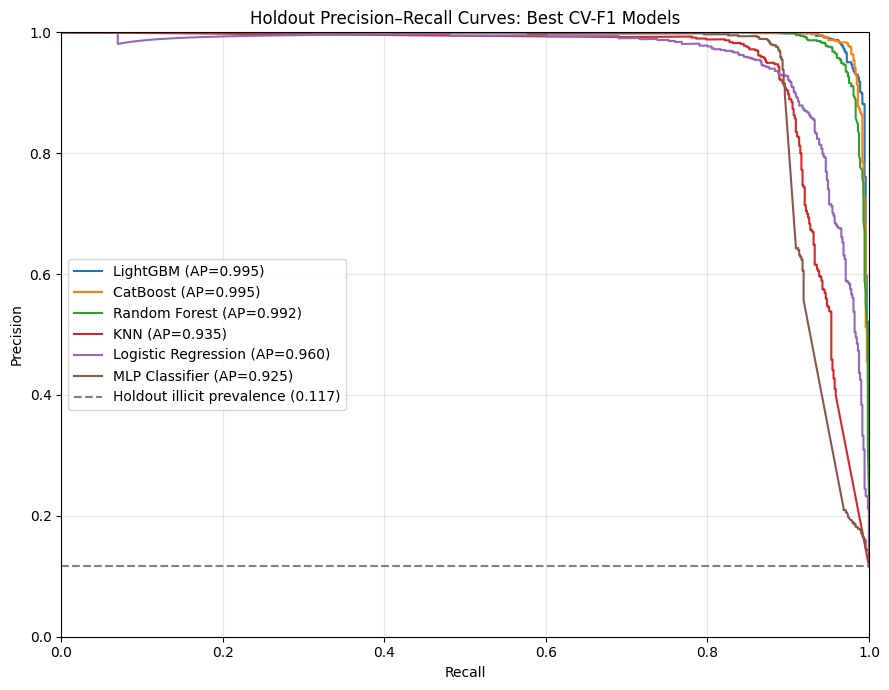

In [14]:
plt.figure(figsize=(9, 7))

for model_name, curve in holdout_curves.items():
    plt.plot(
        curve["recall"],
        curve["precision"],
        label=(
            f"{model_name} "
            f"(AP={curve['average_precision']:.3f})"
        ),
    )

# No-skill reference: the positive-class prevalence in the holdout.
plt.axhline(
    y=y_holdout.mean(),
    color="gray",
    linestyle="--",
    label=f"Holdout illicit prevalence ({y_holdout.mean():.3f})",
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Holdout Precision–Recall Curves: Best CV-F1 Models")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# 2. Compare between log-loss vs pr-auc

* limitation: this is using the same holdout-dataset as earlier to decide what is the best performing model (with the tuned parameters) to choose for log_loss 
* the holdout is no longer fully untouched

In [19]:
# Parameters found using PR-AUC tuning
pr_auc_params = {
    "scale_pos_weight": 3.0,
    "num_leaves": 31,
    "n_estimators": 500,
    "min_child_samples": 50,
    "max_depth": 20,
    "learning_rate": 0.1,
}

# Parameters found using log-loss tuning
log_loss_params = {
    "scale_pos_weight": 3.0,
    "num_leaves": 15,
    "n_estimators": 500,
    "min_child_samples": 20,
    "max_depth": 10,
    "learning_rate": 0.03,
}

def create_lgbm_pipeline(params):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LGBMClassifier(
            objective="binary",
            random_state=100,
            verbosity=-1,
            n_jobs=-1,
            **params,
        )),
    ])

models = {
    "LightGBM tuned on PR-AUC": create_lgbm_pipeline(pr_auc_params),
    "LightGBM tuned on log loss": create_lgbm_pipeline(log_loss_params),
}

In [20]:
X_dev_lgbm = get_X_for_ids(
    train_raw,
    train_id_list,
)

X_holdout_lgbm = get_X_for_ids(
    train_raw,
    test_id_list,
)

y_dev_lgbm = known_by_id.loc[
    train_id_list,
    "label",
].astype(int)

y_holdout_lgbm = known_by_id.loc[
    test_id_list,
    "label",
].astype(int)


In [21]:
holdout_results = []
holdout_predictions = {}

for model_name, model in models.items():
    model.fit(
        X_dev_lgbm,
        y_dev_lgbm,
    )

    p_illicit = model.predict_proba(
        X_holdout_lgbm
    )[:, 1]

    holdout_predictions[model_name] = p_illicit

    hard_predictions = (
        p_illicit >= 0.50
    ).astype(int)

    holdout_results.append({
        "model": model_name,
        "holdout_log_loss": log_loss(
            y_holdout_lgbm,
            p_illicit,
        ),
        "holdout_brier_score": brier_score_loss(
            y_holdout_lgbm,
            p_illicit,
        ),
        "holdout_ROC_AUC": roc_auc_score(
            y_holdout_lgbm,
            p_illicit,
        ),
        "holdout_PR_AUC": average_precision_score(
            y_holdout_lgbm,
            p_illicit,
        ),
        "holdout_precision": precision_score(
            y_holdout_lgbm,
            hard_predictions,
            zero_division=0,
        ),
        "holdout_recall": recall_score(
            y_holdout_lgbm,
            hard_predictions,
            zero_division=0,
        ),
        "holdout_F1": f1_score(
            y_holdout_lgbm,
            hard_predictions,
            zero_division=0,
        ),
        "mean_p_illicit": np.mean(p_illicit),
        "median_p_illicit": np.median(p_illicit),
        "max_p_illicit": np.max(p_illicit),
    })

comparison_df = (
    pd.DataFrame(holdout_results)
    .sort_values(
        "holdout_log_loss",
        ascending=True,
    )
    .reset_index(drop=True)
)

display(comparison_df)

,model,holdout_log_loss,holdout_brier_score,holdout_ROC_AUC,holdout_PR_AUC,holdout_precision,holdout_recall,holdout_F1,mean_p_illicit,median_p_illicit,max_p_illicit
0,LightGBM tuned on log loss,0.019000,0.005048,0.999108,0.995487,0.977809,0.967078,0.972414,0.118287,1.386421e-04,0.999925
1,LightGBM tuned on PR-AUC,0.027243,0.004285,0.998921,0.996113,0.992958,0.967078,0.979847,0.113430,5.591203e-10,1.000000


In [22]:
prediction_comparison = pd.DataFrame({
    "true_label": np.asarray(y_holdout),
    "p_illicit_pr_auc_tuned": holdout_predictions[
        "LightGBM tuned on PR-AUC"
    ],
    "p_illicit_log_loss_tuned": holdout_predictions[
        "LightGBM tuned on log loss"
    ],
})

display(prediction_comparison.head())

,true_label,p_illicit_pr_auc_tuned,p_illicit_log_loss_tuned
0,0,2.859352e-12,0.000006
1,1,1.000000e+00,0.999707
2,0,5.504330e-10,0.000017
3,0,2.574758e-11,0.000047
4,0,7.729327e-10,0.000752


In [23]:
holdout_eval = X_holdout[["time_step"]].copy()
holdout_eval["true_label"] = np.asarray(y_holdout)

holdout_eval["p_pr_auc_tuned"] = holdout_predictions[
    "LightGBM tuned on PR-AUC"
]

holdout_eval["p_log_loss_tuned"] = holdout_predictions[
    "LightGBM tuned on log loss"
]

temporal_comparison = []

for time_step, group in holdout_eval.groupby("time_step"):
    if group["true_label"].nunique() < 2:
        continue

    temporal_comparison.append({
        "time_step": time_step,
        "pr_auc_tuned_log_loss": log_loss(
            group["true_label"],
            group["p_pr_auc_tuned"],
        ),
        "log_loss_tuned_log_loss": log_loss(
            group["true_label"],
            group["p_log_loss_tuned"],
        ),
        "pr_auc_tuned_ROC_AUC": roc_auc_score(
            group["true_label"],
            group["p_pr_auc_tuned"],
        ),
        "log_loss_tuned_ROC_AUC": roc_auc_score(
            group["true_label"],
            group["p_log_loss_tuned"],
        ),
    })

temporal_comparison_df = pd.DataFrame(temporal_comparison)
display(temporal_comparison_df)

,time_step,pr_auc_tuned_log_loss,log_loss_tuned_log_loss,pr_auc_tuned_ROC_AUC,log_loss_tuned_ROC_AUC
0,1,4.321054e-02,0.021553,0.999764,0.999717
1,2,1.699221e-02,0.011606,1.000000,1.000000
2,3,7.905926e-02,0.047816,0.987939,0.994204
3,4,7.626190e-04,0.012923,1.000000,1.000000
4,5,5.661086e-02,0.024285,0.999502,0.999218
5,6,2.536445e-06,0.003120,1.000000,1.000000
6,7,4.172345e-02,0.022723,0.999399,0.999099
7,8,2.928863e-02,0.021574,0.999774,0.999549
8,9,9.833126e-04,0.011274,1.000000,1.000000
9,10,4.558822e-02,0.016902,0.999453,0.999726


Comparing the biggest difference between pr_auc and log_loss, highlights areas where log_loss and pr_auc have given the wrong parameters

the log_loss model is not uniformly error, having some scenarios where log_loss gave high p_illicit to non-illciit rows

In [24]:
prediction_comparison["absolute_difference"] = (
    prediction_comparison["p_illicit_pr_auc_tuned"]
    - prediction_comparison["p_illicit_log_loss_tuned"]
).abs()

display(
    prediction_comparison
    .sort_values("absolute_difference", ascending=False)
    .head(20)
)

,true_label,p_illicit_pr_auc_tuned,p_illicit_log_loss_tuned,absolute_difference
5745,0,0.050847,0.735061,0.684214
2920,1,0.071010,0.725156,0.654146
1156,0,0.025880,0.646882,0.621002
1071,1,0.902082,0.287419,0.614663
3782,1,0.796581,0.186479,0.610102
2936,0,0.005510,0.538115,0.532604
4087,1,0.966215,0.438656,0.527559
3994,0,0.016145,0.538759,0.522614
2870,0,0.015232,0.533474,0.518243
5240,0,0.001964,0.519356,0.517392


In [25]:
display(
    prediction_comparison[
        [
            "p_illicit_pr_auc_tuned",
            "p_illicit_log_loss_tuned",
        ]
    ].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])
)

,p_illicit_pr_auc_tuned,p_illicit_log_loss_tuned
count,6.247000e+03,6.247000e+03
mean,1.134300e-01,1.182871e-01
std,3.155283e-01,3.126299e-01
min,6.893603e-14,6.905919e-07
1%,3.824911e-13,2.409303e-06
5%,1.840492e-12,5.676903e-06
50%,5.591203e-10,1.386421e-04
95%,1.000000e+00,9.994622e-01
99%,1.000000e+00,9.998322e-01
max,1.000000e+00,9.999246e-01
